# Practical SVM


In [1]:
# Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


## 1. Load the dataset

The Breast Cancer Wisconsin dataset contains:

- **569 observations**
- **30 numerical features**
- Two classes:
  - `0 = malignant`
  - `1 = benign`


In [2]:
# Load the dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("\nClass names:", list(data.target_names))
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index={0: "malignant", 1: "benign"}))

X.head()


Dataset shape: (569, 30)

Class names: [np.str_('malignant'), np.str_('benign')]

Class distribution:
target
malignant    212
benign       357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Split the data into training and test sets

We use an **80/20 stratified split**.

`stratify=y` keeps approximately the same malignant/benign class proportions in both the training and test sets.

The test set is kept untouched while we select the SVM hyperparameters.


In [3]:
# 80/20 stratified train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())


Training observations: 455
Test observations: 114

Training class distribution:
target
0    170
1    285
Name: count, dtype: int64

Test class distribution:
target
0    42
1    72
Name: count, dtype: int64


## 3. Create a scaling + SVM pipeline

Feature scaling is important for SVM because SVM calculations depend strongly on distances and feature magnitudes.

Using a `Pipeline` ensures that:

- the scaler is fitted only on the training portion of each cross-validation fold;
- validation data are not used to calculate the scaling parameters;
- data leakage is avoided.


In [4]:
# Create the machine-learning pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

pipeline


Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC())])

## 4. Define the hyperparameter search

We compare:

### Linear SVM
- C = 0.1, 1, 10, 100

### RBF SVM
- C = 0.1, 1, 10, 100
- gamma = 0.001, 0.01, 0.1, 1

The search metric is **Macro F1**, so both classes contribute equally to the model-selection score.


In [5]:
# Hyperparameter combinations to test

param_grid = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10, 100]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": [0.001, 0.01, 0.1, 1]
    }
]

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             n_jobs=-1,
             param_grid=[{'svc__C': [0.1, 1, 10, 100],
                          'svc__kernel': ['linear']},
                         {'svc__C': [0.1, 1, 10, 100],
                          'svc__gamma': [0.001, 0.01, 0.1, 1],
                          'svc__kernel': ['rbf']}],
             return_train_score=True, scoring='f1_macro')

## 5. Best SVM configuration

Grid Search tests the candidate combinations using only the **training data**.

The test set is still untouched at this point.


In [6]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation Macro F1:")
print(f"{grid_search.best_score_:.4f}")


Best parameters:
{'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}

Best mean cross-validation Macro F1:
0.9739


With the fixed split and search settings used here, the selected model should be:

\[
\text{RBF kernel}, \quad C = 10, \quad \gamma = 0.01
\]

This does **not** mean these values are universally best. They are the best among the combinations tested for this dataset and this experimental setup.


## 6. View the top cross-validation results

This table shows which SVM configurations performed best during cross-validation.


In [7]:
# Convert Grid Search results to a readable table

results = pd.DataFrame(grid_search.cv_results_)

columns_to_show = [
    "param_svc__kernel",
    "param_svc__C",
    "param_svc__gamma",
    "mean_test_score",
    "std_test_score"
]

top_results = (
    results[columns_to_show]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_results


,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
0,rbf,10.0,0.010,0.973888,0.017677
1,linear,0.1,NaN,0.973853,0.011931
2,rbf,1.0,0.010,0.969041,0.016283
3,rbf,100.0,0.001,0.969037,0.012363
4,rbf,10.0,0.001,0.968758,0.022824
5,rbf,100.0,0.010,0.962374,0.013461
6,linear,10.0,NaN,0.962371,0.022842
7,linear,1.0,NaN,0.962250,0.017585
8,rbf,1.0,0.100,0.953323,0.012853
9,rbf,0.1,0.010,0.942078,0.014347


## 7. Evaluate the selected model on the test set

Only after hyperparameter selection is complete do we evaluate the final model on the previously untouched test data.


In [8]:
# Predict the test observations

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
cm = confusion_matrix(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1:      {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")

print("\nConfusion Matrix:")
print(cm)


Test Accuracy: 0.9825 (98.25%)
Macro F1:      0.9812 (98.12%)

Confusion Matrix:
[[41  1]
 [ 1 71]]


### Expected confusion matrix

Rows represent the **actual class** and columns represent the **predicted class**:

| Actual | Predicted Malignant | Predicted Benign |
|---|---:|---:|
| Malignant | 41 | 1 |
| Benign | 1 | 71 |

Therefore:

- **112 out of 114** test observations are classified correctly.
- **1 malignant case is predicted as benign.**
- **1 benign case is predicted as malignant.**


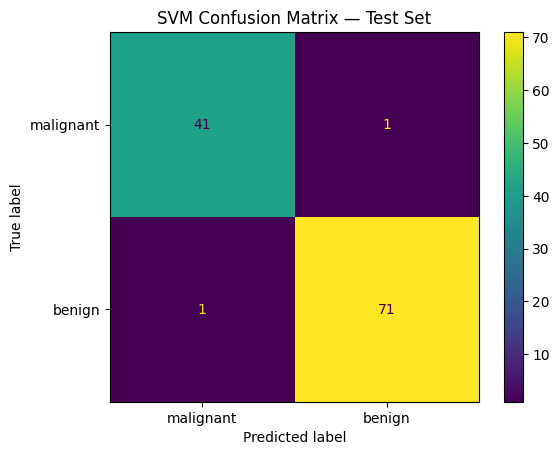

In [9]:
# Graphical confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()
plt.title("SVM Confusion Matrix — Test Set")
plt.show()


## 8. Classification report

The classification report shows precision, recall, and F1 score separately for the malignant and benign classes.


In [11]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        digits=4
    )
)


              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



## 9. Summary

Using this workflow:

- Dataset: **Breast Cancer Wisconsin**
- Observations: **569**
- Features: **30**
- Split: **80% training / 20% testing**
- Split type: **stratified**
- Preprocessing: **StandardScaler**
- Hyperparameter selection: **Grid Search**
- Validation method: **5-fold stratified cross-validation**
- Search metric: **Macro F1**
- Best kernel: **RBF**
- Best C: **10**
- Best gamma: **0.01**
- Test accuracy: **about 98.2%**
- Test Macro F1: **about 98.1%**
- Test errors: **2 out of 114 observations**
